# AHP – Risque d'inondation (Casablanca-Settat, mailles 100 m)
Suit le diagramme de classes : `CalculAHP`, `CritereAHP`, `ComparaisonPaire`, `ScoreRisque`.

In [20]:
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd

# --- Racine du projet
ROOT = Path.cwd()
if ROOT.name == "scripts":
    ROOT = ROOT.parent

DOSSIER_MAILLES = ROOT / "donnees_traitees" / "mailles"   # input
DOSSIER_AHP     = ROOT / "donnees_traitees" / "ahp"       # output
DOSSIER_AHP.mkdir(parents=True, exist_ok=True)

CSV_IN = DOSSIER_MAILLES / "mailles_100m_normalisees.csv"
OUT = DOSSIER_AHP

SCENARIO = "base"
CALCUL_ID = 1

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## 1. Paramètres AHP (à ajuster)
`NIVEAUX` : importance 1-9 par critère, sert à générer la matrice de Saaty. `OVERRIDES` : jugements manuels (i, j) → valeur Saaty. `SENS` : `benefit` = valeur haute ⇒ risque haut, `cost` = l'inverse.

In [27]:
NIVEAUX = {
    "hand_moy": 7, "flux_max_log": 6, "twi_moy": 6, "pct_impermeable": 6,
    "distance_oued": 6, "depression_moy": 5, "ruissel_moy": 5,
    "pente_moy": 4, "densite_bati": 4, "densite_routes": 3,
    "distance_secours": 3, "indice_equip": 2,
}
OVERRIDES = {
    # ("hand_moy", "twi_moy"): 3,
}
SENS = {c: "benefit" for c in NIVEAUX}

RI = {1: 0, 2: 0, 3: .58, 4: .90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41,
      9: 1.45, 10: 1.49, 11: 1.51, 12: 1.54, 13: 1.56, 14: 1.57, 15: 1.59}
SAATY = np.array([1/9, 1/8, 1/7, 1/6, 1/5, 1/4, 1/3, 1/2, 1, 2, 3, 4, 5, 6, 7, 8, 9])

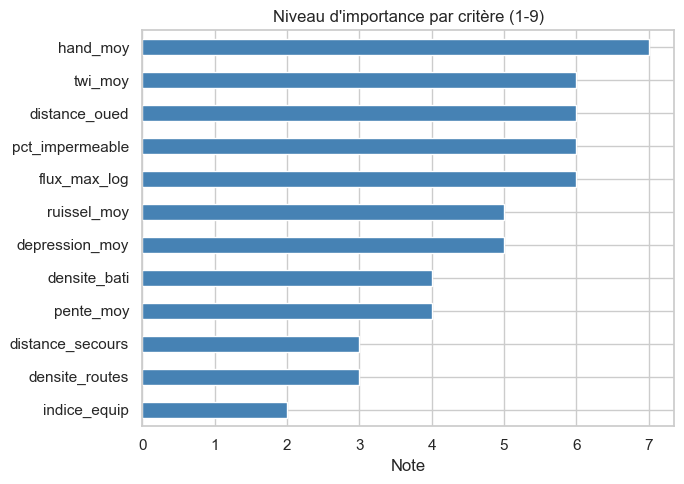

In [28]:
s = pd.Series(NIVEAUX).sort_values()
s.plot.barh(figsize=(7, 5), color="steelblue")
plt.title("Niveau d'importance par critère (1-9)")
plt.xlabel("Note")
plt.tight_layout(); plt.show()

## 2. Fonctions

In [29]:
def saaty_round(x):
    return SAATY[np.argmin(np.abs(SAATY - x))]

def matrice_saaty(criteres):
    n = len(criteres)
    A = np.ones((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            ci, cj = criteres[i], criteres[j]
            d = NIVEAUX[ci] - NIVEAUX[cj]
            v = 1 + d if d >= 0 else 1 / (1 - d)
            v = saaty_round(v)
            if (ci, cj) in OVERRIDES:
                v = OVERRIDES[(ci, cj)]
            elif (cj, ci) in OVERRIDES:
                v = 1 / OVERRIDES[(cj, ci)]
            A[i, j], A[j, i] = v, 1 / v
    return A

def calculer_poids(A):
    """Vecteur propre principal + lambda_max."""
    vals, vecs = np.linalg.eig(A)
    k = np.argmax(vals.real)
    w = np.abs(vecs[:, k].real)
    return w / w.sum(), vals[k].real

def verifier_coherence(lambda_max, n):
    ci = (lambda_max - n) / (n - 1)
    cr = ci / RI[n] if RI[n] else 0.0
    return ci, cr

def classer(score):
    """5 classes par seuils réguliers sur le score min-max (1 = très faible ... 5 = très élevé)."""
    s = (score - score.min()) / (score.max() - score.min())
    return pd.cut(s, [-1e-9, .2, .4, .6, .8, 1.0], labels=[1, 2, 3, 4, 5]).astype(int)

## 3. Poids et cohérence

In [30]:
df = pd.read_csv(CSV_IN)
criteres = list(NIVEAUX)
n = len(criteres)

A = matrice_saaty(criteres)
w, lam = calculer_poids(A)
ci, cr = verifier_coherence(lam, n)
print(f"lambda_max={lam:.4f}  CI={ci:.4f}  CR={cr:.4f} ->",
      "OK (CR<0.10)" if cr < 0.10 else "INCOHÉRENT : revoir les jugements")

poids = pd.Series(w, index=criteres).sort_values(ascending=False)
poids.round(4)

lambda_max=12.1778  CI=0.0162  CR=0.0105 -> OK (CR<0.10)


hand_moy            0.1961
flux_max_log        0.1220
twi_moy             0.1220
pct_impermeable     0.1220
distance_oued       0.1220
depression_moy      0.0733
ruissel_moy         0.0733
pente_moy           0.0454
densite_bati        0.0454
densite_routes      0.0291
distance_secours    0.0291
indice_equip        0.0202
dtype: float64

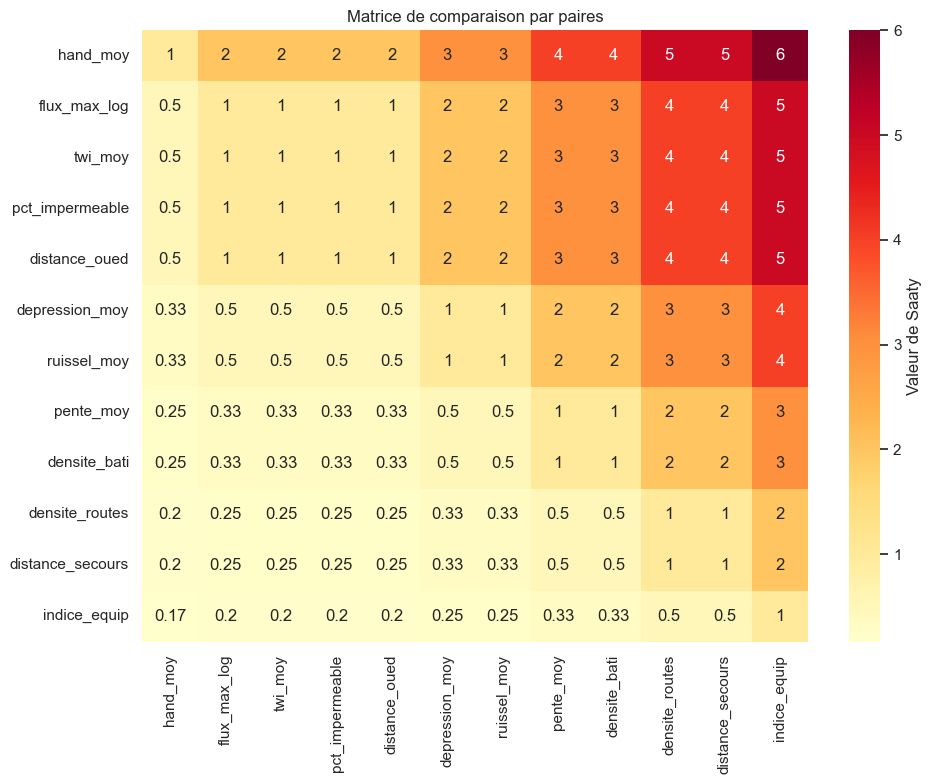

In [31]:
M = pd.DataFrame(A, index=criteres, columns=criteres)
plt.figure(figsize=(10, 8))
sns.heatmap(M, annot=True, fmt=".2g", cmap="YlOrRd", cbar_kws={"label": "Valeur de Saaty"})
plt.title("Matrice de comparaison par paires")
plt.tight_layout(); plt.show()

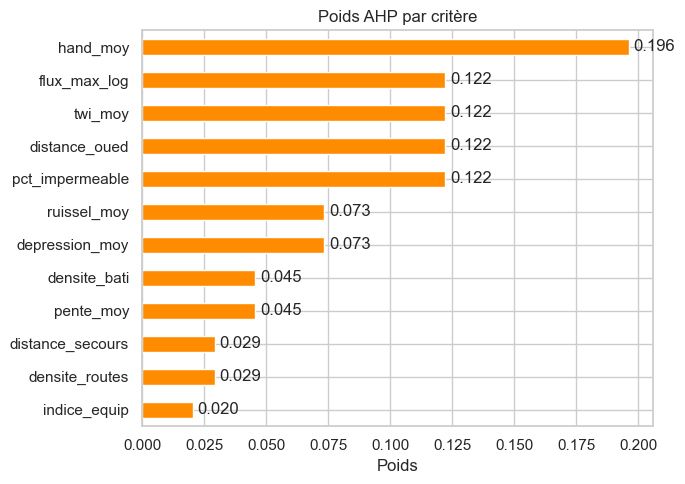

In [32]:
p = poids.sort_values()
ax = p.plot.barh(figsize=(7, 5), color="darkorange")
for i, v in enumerate(p):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center")
plt.title("Poids AHP par critère")
plt.xlabel("Poids")
plt.tight_layout(); plt.show()

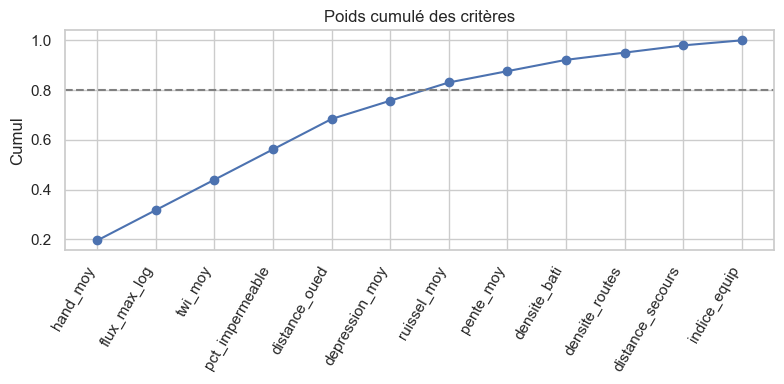

In [33]:
pc = poids.cumsum()
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(pc) + 1), pc.values, marker="o")
plt.xticks(range(1, len(pc) + 1), pc.index, rotation=60, ha="right")
plt.axhline(0.8, color="gray", linestyle="--")
plt.title("Poids cumulé des critères")
plt.ylabel("Cumul")
plt.tight_layout(); plt.show()

## 4. Tables du diagramme

In [34]:
calcul = pd.DataFrame([{
    "id": CALCUL_ID, "date_calcul": datetime.now().isoformat(timespec="seconds"),
    "scenario": SCENARIO, "lambda_max": lam,
    "indice_coherence": ci, "ratio_coherence": cr}])

critere = pd.DataFrame({"id": range(1, n + 1), "calcul_id": CALCUL_ID,
                        "variable": criteres, "sens": [SENS[c] for c in criteres],
                        "poids": w})

comparaison = pd.DataFrame([{"calcul_id": CALCUL_ID, "critere_i": i + 1, "critere_j": j + 1,
                             "valeur_saaty": A[i, j]}
                            for i in range(n) for j in range(i + 1, n)])

calcul.to_csv(OUT / "calcul_ahp.csv", index=False)
critere.to_csv(OUT / "critere_ahp.csv", index=False)
comparaison.to_csv(OUT / "comparaison_paire.csv", index=False)
critere

,id,calcul_id,variable,sens,poids
0,1,1,hand_moy,benefit,0.196072
1,2,1,flux_max_log,benefit,0.122005
2,3,1,twi_moy,benefit,0.122005
3,4,1,pct_impermeable,benefit,0.122005
4,5,1,distance_oued,benefit,0.122005
5,6,1,depression_moy,benefit,0.073343
6,7,1,ruissel_moy,benefit,0.073343
7,8,1,pente_moy,benefit,0.045404
8,9,1,densite_bati,benefit,0.045404
9,10,1,densite_routes,benefit,0.029084


## 5. Score de risque par maille (`ScoreRisque.calculer()`)

In [35]:
X = df[criteres].to_numpy(dtype="float32")
sgn = np.array([1 if SENS[c] == "benefit" else -1 for c in criteres])
X = np.where(sgn > 0, X, 1 - X)
valeur = X @ w.astype("float32")

score = pd.DataFrame({"maille_id": df["id"], "calcul_id": CALCUL_ID,
                      "valeur": valeur, "classe": classer(pd.Series(valeur))})
score.to_csv(OUT / "score_risque.csv", index=False)
score["classe"].value_counts().sort_index()

classe
1      13958
2    1182721
3     778934
4      43846
5       1246
Name: count, dtype: int64

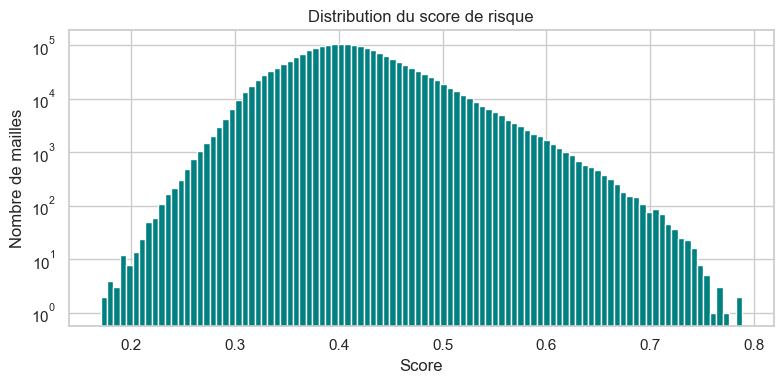

In [36]:
plt.figure(figsize=(8, 4))
plt.hist(score["valeur"], bins=100, color="teal")
plt.title("Distribution du score de risque")
plt.xlabel("Score"); plt.ylabel("Nombre de mailles")
plt.yscale("log")
plt.tight_layout(); plt.show()

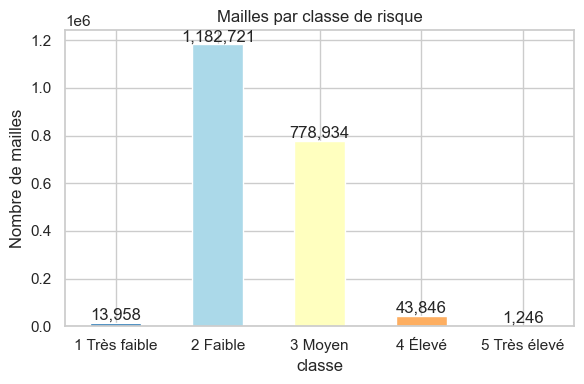

In [37]:
couleurs = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]
cl = score["classe"].value_counts().sort_index()
ax = cl.plot.bar(color=couleurs, figsize=(6, 4))
for i, v in enumerate(cl):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_xticklabels(["1 Très faible", "2 Faible", "3 Moyen", "4 Élevé", "5 Très élevé"], rotation=0)
plt.title("Mailles par classe de risque")
plt.ylabel("Nombre de mailles")
plt.tight_layout(); plt.show()

In [43]:
import geopandas as gpd
import pyogrio
from matplotlib.colors import ListedColormap

fichier = DOSSIER_MAILLES / "mailles_100m.gpkg"

# 1. voir les couches et leurs colonnes
for couche in pyogrio.list_layers(fichier)[:, 0]:
    g = gpd.read_file(fichier, layer=couche, rows=2)
    print(couche, "->", list(g.columns))

mailles_100m -> ['maille_id', 'surface_m2', 'centroide_x', 'centroide_y', 'commune_id', 'geometry']
maille_centroide -> ['id', 'geometry']
maille -> ['id', 'centroide', 'taille_m', 'commune_id', 'geometry']


2020705 mailles jointes sur 2020705


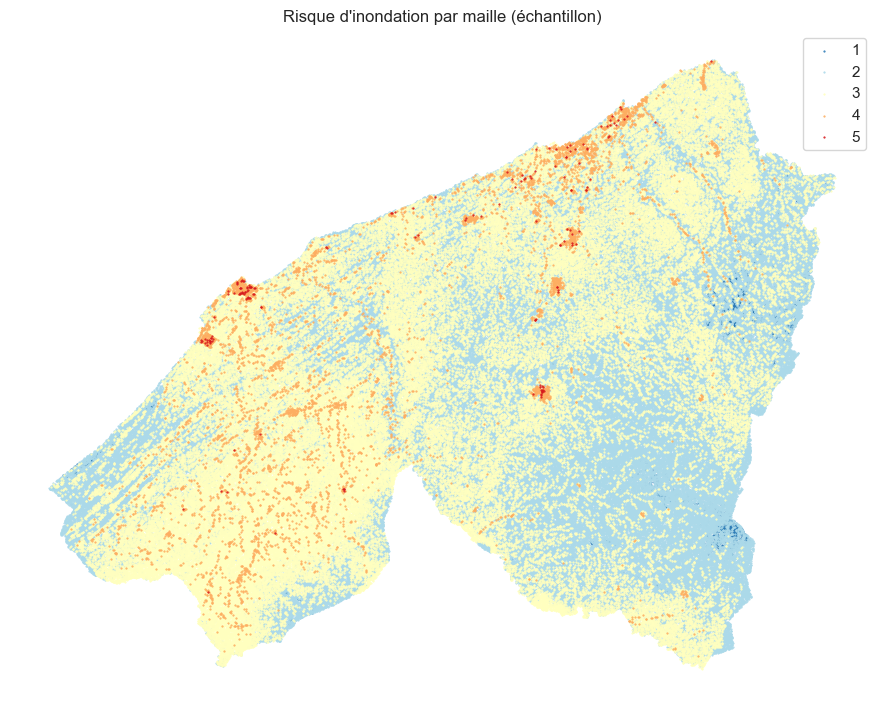

In [44]:
couleurs = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]

pts = gpd.read_file(fichier, layer="maille_centroide", fid_as_index=True)

# trouver la colonne identifiant
candidats = [c for c in ["id", "maille_id", "id_maille", "ID", "fid"] if c in pts.columns]
if candidats:
    pts = pts.rename(columns={candidats[0]: "maille_id"})
else:
    pts["maille_id"] = pts.index      # sinon on utilise le fid du GPKG
    print("Aucune colonne id : jointure par fid. Vérifie que la carte est cohérente.")

pts = pts[["maille_id", "geometry"]].merge(
    score[["maille_id", "classe"]], on="maille_id")
print(len(pts), "mailles jointes sur", len(score))

pts = pts.sample(min(300_000, len(pts)), random_state=0)

fig, ax = plt.subplots(figsize=(9, 9))
pts.plot(column="classe", cmap=ListedColormap(couleurs), markersize=0.3,
         legend=True, categorical=True, ax=ax)
ax.set_title("Risque d'inondation par maille (échantillon)")
ax.set_axis_off()
plt.tight_layout(); plt.show()